In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
from pathlib import Path

# Training 압축파일 경로입니다.
train_zip = Path(
    "/content/drive/MyDrive/project/data/TL_카드거래.zip"
)

# 압축을 해제할 폴더입니다.
train_dir = Path("/content/TL_카드거래_train")
train_dir.mkdir(exist_ok=True)

# Training 압축파일을 해제합니다.
with zipfile.ZipFile(train_zip, "r") as zip_file:
    zip_file.extractall(train_dir)

print("Training 압축 해제 완료")

Training 압축 해제 완료


In [ ]:
# Validation 압축파일 경로입니다.
valid_zip = Path(
    "/content/drive/MyDrive/project/data/VL_카드거래.zip"
)

# 압축을 해제할 폴더입니다.
valid_dir = Path("/content/TL_카드거래_valid")
valid_dir.mkdir(exist_ok=True)

# Validation 압축파일을 해제합니다.
with zipfile.ZipFile(valid_zip, "r") as zip_file:
    zip_file.extractall(valid_dir)

print("Validation 압축 해제 완료")

Validation 압축 해제 완료


In [ ]:
# 압축 해제된 CSV 파일을 모두 찾습니다.
train_files = sorted(train_dir.rglob("*.csv"))
valid_files = sorted(valid_dir.rglob("*.csv"))

print("Training CSV 개수:", len(train_files))
print("Validation CSV 개수:", len(valid_files))

print("\n첫 번째 Training 파일:")
print(train_files[0] if train_files else "CSV 파일 없음")

print("\n첫 번째 Validation 파일:")
print(valid_files[0] if valid_files else "CSV 파일 없음")

Training CSV 개수: 16
Validation CSV 개수: 16

첫 번째 Training 파일:
/content/TL_카드거래_train/TL_카드거래/21-2_카드데이터_2021_1분기.csv

첫 번째 Validation 파일:
/content/TL_카드거래_valid/VL_카드거래/21-2_카드데이터_2021_1분기.csv


In [ ]:
import pandas as pd
from pathlib import Path

# 압축 해제된 폴더 경로입니다.
train_dir = Path("/content/TL_카드거래_train")
valid_dir = Path("/content/TL_카드거래_valid")

# 하위 폴더의 CSV 파일을 모두 찾습니다.
train_files = sorted(train_dir.rglob("*.csv"))
valid_files = sorted(valid_dir.rglob("*.csv"))

print("Training CSV 개수:", len(train_files))
print("Validation CSV 개수:", len(valid_files))

# Training CSV를 모두 합칩니다.
train_df = pd.concat(
    [
        pd.read_csv(file, low_memory=False)
        for file in train_files
    ],
    ignore_index=True,
)

# Validation CSV를 모두 합칩니다.
valid_df = pd.concat(
    [
        pd.read_csv(file, low_memory=False)
        for file in valid_files
    ],
    ignore_index=True,
)

print("Training 데이터:", train_df.shape)
print("Validation 데이터:", valid_df.shape)

Training CSV 개수: 16
Validation CSV 개수: 16
Training 데이터: (1735885, 32)
Validation 데이터: (216986, 32)


## 2. 전체 데이터 통합 및 Train·Validation·Test 분할

Training 데이터와 기존 Validation 데이터를 하나로 합친다.

이후 전체 데이터에서 Test 데이터를 20% 분리하고, 남은 데이터의 12.5%를 Validation 데이터로 분리한다.

최종 데이터 비율은 다음과 같다.

- Train: 70%
- Validation: 10%
- Test: 20%

`stratify`를 사용하여 Train, Validation, Test 데이터의 이상거래 비율이 비슷하게 유지되도록 한다.

`random_state=42`를 설정하여 코드를 다시 실행해도 동일한 방식으로 데이터가 분할되도록 한다.

Test 데이터는 모델 학습과 임계값 선택에 사용하지 않고, 최종 성능 평가에만 사용한다.

In [5]:
# 데이터를 나누기 위한 함수를 가져옵니다.
from sklearn.model_selection import train_test_split

# 정답 컬럼명을 지정합니다.
TARGET = "이상거래여부"

# Training과 Validation 데이터를 하나로 합칩니다.
all_df = pd.concat(
    [train_df, valid_df],
    ignore_index=True,
)

# 전체 데이터의 20%를 Test로 분리합니다.
train_valid_df, test_df = train_test_split(
    all_df,
    test_size=0.2,
    random_state=42,
    stratify=all_df[TARGET],
)

# 남은 데이터의 12.5%를 Validation으로 분리합니다.
train_df, valid_df = train_test_split(
    train_valid_df,
    test_size=0.125,
    random_state=42,
    stratify=train_valid_df[TARGET],
)

# 인덱스를 다시 정리합니다.
train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# 데이터 크기를 확인합니다.
print("전체 데이터:", all_df.shape)
print("Train:", train_df.shape)
print("Validation:", valid_df.shape)
print("Test:", test_df.shape)

# 이상거래 비율을 확인합니다.
print("Train 이상거래 비율:", f"{train_df[TARGET].mean():.2%}")
print("Validation 이상거래 비율:", f"{valid_df[TARGET].mean():.2%}")
print("Test 이상거래 비율:", f"{test_df[TARGET].mean():.2%}")

전체 데이터: (1952871, 32)
Train: (1367009, 32)
Validation: (195287, 32)
Test: (390575, 32)
Train 이상거래 비율: 3.69%
Validation 이상거래 비율: 3.69%
Test 이상거래 비율: 3.69%


## 3. 입력 변수와 정답 분리 및 데이터 누수 방지

이상거래 여부를 예측하기 위해 모델 입력 변수와 정답 변수를 분리한다.

`이상거래유형`과 `이상거래설명`은 이상거래 여부를 직접적으로 암시할 수 있으므로 모델 입력에서 제외한다.

또한 `이상거래여부` 정답 컬럼도 모델 입력에 포함하지 않는다.

현재 사용하는 원본 변수는 승인일자, 승인시간대, 승인금액, 카드 이용한도, 국내외 여부, 온라인 거래 여부 등 실제 거래 시점에 확인할 수 있는 변수로 구성하였다.

마지막으로 Train, Validation, Test 모두에서 정답 및 누수 컬럼이 입력 변수에 포함되지 않았는지 확인한다.

In [6]:
# 정답을 직접 암시할 수 있는 누수 컬럼입니다.
LEAKAGE_COLUMNS = [
    "이상거래유형",
    "이상거래설명",
]


# 모델 입력에 사용할 원본 변수입니다.
SOURCE_FEATURES = [
    "승인일자",
    "승인시간대",
    "카드KEY",
    "통합승인금액",
    "국내해외여부",
    "카드이용한도금액",
    "가맹점여부_신규",
    "인터넷판매여부",
    "경과일수_최종이용일자",
]


# Train, Validation, Test의 입력 변수를 분리합니다.
X_train_raw = train_df[SOURCE_FEATURES].copy()
X_valid_raw = valid_df[SOURCE_FEATURES].copy()
X_test_raw = test_df[SOURCE_FEATURES].copy()


# Train, Validation, Test의 정답을 분리합니다.
y_train = train_df[TARGET].copy()
y_valid = valid_df[TARGET].copy()
y_test = test_df[TARGET].copy()


# 누수 컬럼과 정답이 입력 변수에 포함되지 않았는지 확인합니다.
for column in [TARGET, *LEAKAGE_COLUMNS]:
    assert column not in X_train_raw.columns
    assert column not in X_valid_raw.columns
    assert column not in X_test_raw.columns


# 분리 결과를 확인합니다.
print("Train 입력:", X_train_raw.shape)
print("Validation 입력:", X_valid_raw.shape)
print("Test 입력:", X_test_raw.shape)
print("Train 정답:", y_train.shape)
print("Validation 정답:", y_valid.shape)
print("Test 정답:", y_test.shape)

Train 입력: (1367009, 9)
Validation 입력: (195287, 9)
Test 입력: (390575, 9)
Train 정답: (1367009,)
Validation 정답: (195287,)
Test 정답: (390575,)


## 4. 원본 변수 변환 및 고도화 파생변수 생성

원본 거래 데이터를 숫자형과 날짜형으로 변환하고, 이상거래 탐지에 필요한 파생변수를 생성한다.

기본 모델에서 사용한 승인금액, 거래시간, 카드 한도, 해외거래 여부 등의 변수에 더해 고도화 모델에서는 `남녀구분코드`와 `연령`을 추가한다.

카드별 평균 승인금액은 Train 데이터에서만 계산하여 Validation과 Test 데이터의 정보가 학습에 섞이지 않도록 한다.

생성된 Train, Validation, Test 데이터가 동일한 피처 구조를 가지는지 확인한다.

In [7]:
# 정답을 직접 암시할 수 있는 누수 컬럼입니다.
LEAKAGE_COLUMNS = [
    "이상거래유형",
    "이상거래설명",
]


# 고도화 모델에 사용할 원본 변수입니다.
SOURCE_FEATURES = [
    "승인일자",
    "승인시간대",
    "카드KEY",
    "통합승인금액",
    "국내해외여부",
    "카드이용한도금액",
    "가맹점여부_신규",
    "인터넷판매여부",
    "경과일수_최종이용일자",
    "연령",
    "남녀구분코드",
]


# Train 입력 데이터를 생성합니다.
X_train_raw = train_df[
    SOURCE_FEATURES
].copy()


# Validation 입력 데이터를 생성합니다.
X_valid_raw = valid_df[
    SOURCE_FEATURES
].copy()


# Test 입력 데이터를 생성합니다.
X_test_raw = test_df[
    SOURCE_FEATURES
].copy()


# Train 정답 데이터를 생성합니다.
y_train = train_df[TARGET].copy()


# Validation 정답 데이터를 생성합니다.
y_valid = valid_df[TARGET].copy()


# Test 정답 데이터를 생성합니다.
y_test = test_df[TARGET].copy()


# 누수 컬럼과 정답이 입력에 없는지 확인합니다.
for column in [TARGET, *LEAKAGE_COLUMNS]:

    # Train 입력을 확인합니다.
    assert column not in X_train_raw.columns

    # Validation 입력을 확인합니다.
    assert column not in X_valid_raw.columns

    # Test 입력을 확인합니다.
    assert column not in X_test_raw.columns


# 고도화 변수 포함 여부를 확인합니다.
assert "연령" in X_train_raw.columns
assert "남녀구분코드" in X_train_raw.columns


# 입력 데이터 크기를 출력합니다.
print("Train 입력:", X_train_raw.shape)
print("Validation 입력:", X_valid_raw.shape)
print("Test 입력:", X_test_raw.shape)


# 정답 데이터 크기를 출력합니다.
print("Train 정답:", y_train.shape)
print("Validation 정답:", y_valid.shape)
print("Test 정답:", y_test.shape)

Train 입력: (1367009, 11)
Validation 입력: (195287, 11)
Test 입력: (390575, 11)
Train 정답: (1367009,)
Validation 정답: (195287,)
Test 정답: (390575,)


## 7. 고도화 파생변수 생성

원본 거래 데이터를 숫자형과 날짜형으로 변환하고, 이상거래 탐지에 필요한 파생변수를 생성한다.

기존 변수에 `연령`과 `남녀구분코드`를 추가하여 고도화 모델용 피처를 구성한다.

In [8]:
# Train 승인금액을 숫자형으로 변환합니다.
train_amount = pd.to_numeric(
    X_train_raw["통합승인금액"],
    errors="coerce",
)

# 결측 카드의 평균금액 대체값을 계산합니다.
fallback = train_amount.median()

# Train 카드별 평균 승인금액을 계산합니다.
card_avg_map = train_amount.groupby(
    X_train_raw["카드KEY"]
).mean()

# 각 데이터에 Train 기준 카드 평균금액을 연결합니다.
train_card_avg = X_train_raw["카드KEY"].map(
    card_avg_map
).fillna(fallback)

valid_card_avg = X_valid_raw["카드KEY"].map(
    card_avg_map
).fillna(fallback)

test_card_avg = X_test_raw["카드KEY"].map(
    card_avg_map
).fillna(fallback)


# 파생변수를 생성하는 함수를 정의합니다.
def make_features(df, card_avg):

    # 주요 숫자형 변수를 변환합니다.
    amount = pd.to_numeric(
        df["통합승인금액"],
        errors="coerce",
    )

    limit_ = pd.to_numeric(
        df["카드이용한도금액"],
        errors="coerce",
    )

    hour = pd.to_numeric(
        df["승인시간대"],
        errors="coerce",
    )

    overseas = pd.to_numeric(
        df["국내해외여부"],
        errors="coerce",
    )

    online = pd.to_numeric(
        df["인터넷판매여부"],
        errors="coerce",
    )

    # 승인일자를 날짜형으로 변환합니다.
    date = pd.to_datetime(
        df["승인일자"].astype("string"),
        format="%Y%m%d",
        errors="coerce",
    )

    # 모델 입력 피처를 생성합니다.
    return pd.DataFrame({
        "amt": amount,
        "limit": limit_,
        "hour": hour,
        "age": pd.to_numeric(
            df["연령"],
            errors="coerce",
        ),
        "gender": pd.to_numeric(
            df["남녀구분코드"],
            errors="coerce",
        ),
        "is_overseas": overseas,
        "is_new_merchant": pd.to_numeric(
            df["가맹점여부_신규"],
            errors="coerce",
        ),
        "is_online": online,
        "days_since_last": pd.to_numeric(
            df["경과일수_최종이용일자"],
            errors="coerce",
        ),
        "amt_to_limit_ratio": amount / limit_.where(
            limit_ > 0
        ),
        "limit_is_zero": limit_.eq(0).astype(int),
        "is_midnight": hour.between(0, 5).astype(int),
        "is_weekend": date.dt.dayofweek.ge(5).astype(int),
        "amt_diff_from_user_avg": amount - card_avg,
        "overseas_online_risk": (
            overseas.eq(1) & online.eq(1)
        ).astype(int),
    })


# Train 피처를 생성합니다.
X_train = make_features(
    X_train_raw,
    train_card_avg,
)

# Validation 피처를 생성합니다.
X_valid = make_features(
    X_valid_raw,
    valid_card_avg,
)

# Test 피처를 생성합니다.
X_test = make_features(
    X_test_raw,
    test_card_avg,
)

# 피처 크기를 확인합니다.
print("Train 피처:", X_train.shape)
print("Validation 피처:", X_valid.shape)
print("Test 피처:", X_test.shape)

Train 피처: (1367009, 15)
Validation 피처: (195287, 15)
Test 피처: (390575, 15)


## 8. 고도화 피처 결측치 처리

파생변수 생성 과정에서 발생한 결측치와 무한대 값을 처리한다.

숫자형 변수는 Train 데이터에서 계산한 중앙값으로 대체하고, 범주형 변수는 알 수 없는 값인 `2`로 대체한다.

Train에서 계산한 기준을 Validation과 Test에도 동일하게 적용하여 데이터 누수를 방지한다.

In [9]:
import numpy as np

In [10]:
# 숫자형 피처 목록을 정의합니다.
numeric_cols = [
    "amt",
    "limit",
    "hour",
    "age",
    "days_since_last",
    "amt_to_limit_ratio",
    "amt_diff_from_user_avg",
]


# 범주형 피처 목록을 정의합니다.
categorical_cols = [
    "gender",
    "is_overseas",
    "is_new_merchant",
    "is_online",
    "limit_is_zero",
    "is_midnight",
    "is_weekend",
    "overseas_online_risk",
]


# 피처를 복사합니다.
X_train_clean = X_train.copy()
X_valid_clean = X_valid.copy()
X_test_clean = X_test.copy()


# 무한대 값을 결측치로 변환합니다.
for data in [
    X_train_clean,
    X_valid_clean,
    X_test_clean,
]:
    data[numeric_cols] = data[numeric_cols].replace(
        [np.inf, -np.inf],
        np.nan,
    )


# Train 기준 중앙값을 계산합니다.
train_medians = X_train_clean[numeric_cols].median()


# 숫자형 결측치를 Train 중앙값으로 대체합니다.
for data in [
    X_train_clean,
    X_valid_clean,
    X_test_clean,
]:
    data[numeric_cols] = data[numeric_cols].fillna(
        train_medians
    )


# 범주형 결측치를 2로 대체합니다.
for data in [
    X_train_clean,
    X_valid_clean,
    X_test_clean,
]:
    data[categorical_cols] = data[categorical_cols].fillna(2)


# 결측치 처리 결과를 확인합니다.
print(
    "Train 결측치:",
    X_train_clean.isna().sum().sum(),
)

print(
    "Validation 결측치:",
    X_valid_clean.isna().sum().sum(),
)

print(
    "Test 결측치:",
    X_test_clean.isna().sum().sum(),
)

Train 결측치: 0
Validation 결측치: 0
Test 결측치: 0


## 9. 고도화 피처 스케일링

숫자형 피처의 값 범위를 조정하기 위해 RobustScaler를 적용한다.

Scaler는 Train 데이터로만 학습하고, Validation과 Test에는 Train에서 계산한 기준을 그대로 적용한다.

In [11]:
# RobustScaler를 가져옵니다.
from sklearn.preprocessing import RobustScaler


# RobustScaler를 생성합니다.
scaler = RobustScaler()


# 데이터를 복사합니다.
X_train_scaled = X_train_clean.copy()
X_valid_scaled = X_valid_clean.copy()
X_test_scaled = X_test_clean.copy()


# Train 데이터로 기준을 계산하고 변환합니다.
X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_clean[numeric_cols]
)


# Train 기준을 Validation에 적용합니다.
X_valid_scaled[numeric_cols] = scaler.transform(
    X_valid_clean[numeric_cols]
)


# Train 기준을 Test에 적용합니다.
X_test_scaled[numeric_cols] = scaler.transform(
    X_test_clean[numeric_cols]
)


# 변환 결과를 확인합니다.
print("Train:", X_train_scaled.shape)
print("Validation:", X_valid_scaled.shape)
print("Test:", X_test_scaled.shape)

Train: (1367009, 15)
Validation: (195287, 15)
Test: (390575, 15)


## 10. 고도화 Train 데이터에 SMOTENC 적용

연령, 성별 코드와 같은 범주형 피처를 고려하여 Train 데이터에만 SMOTENC를 적용한다.

Validation과 Test 데이터에는 SMOTENC를 적용하지 않고 원본 분포를 유지한다.

SMOTENC 비율은 Validation F1-score가 가장 높았던 `0.3`으로 설정한다.

In [12]:
# SMOTENC를 가져옵니다.
from imblearn.over_sampling import SMOTENC


# 범주형 피처의 열 위치를 찾습니다.
categorical_indices = [
    X_train_scaled.columns.get_loc(column)
    for column in categorical_cols
]


# 이상거래 비율을 정상거래의 30%까지 늘립니다.
smotenc = SMOTENC(
    categorical_features=categorical_indices,
    sampling_strategy=0.3,
    random_state=42,
)


# 적용 전 클래스 분포를 확인합니다.
print("[SMOTENC 적용 전]")
print(y_train.value_counts().sort_index())


# Train 데이터에만 SMOTENC를 적용합니다.
X_train_resampled, y_train_resampled = (
    smotenc.fit_resample(
        X_train_scaled,
        y_train,
    )
)


# 적용 후 클래스 분포를 확인합니다.
print("\n[SMOTENC 적용 후]")
print(y_train_resampled.value_counts().sort_index())


# 데이터 크기를 확인합니다.
print("\nTrain:", X_train_resampled.shape)
print("Validation:", X_valid_scaled.shape)
print("Test:", X_test_scaled.shape)

[SMOTENC 적용 전]
이상거래여부
0    1316604
1      50405
Name: count, dtype: int64

[SMOTENC 적용 후]
이상거래여부
0    1316604
1     394981
Name: count, dtype: int64

Train: (1711585, 15)
Validation: (195287, 15)
Test: (390575, 15)


## 11. 고도화 LightGBM 모델 학습 및 평가

연령과 성별 변수가 추가된 15개 피처와 SMOTENC가 적용된 Train 데이터를 사용하여 LightGBM을 학습한다.

임계값은 기존 실험과 동일하게 0.55로 설정하여 기본 모델과 성능을 비교한다.

In [13]:
# LightGBM과 평가 도구를 가져옵니다.
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score,
)


# LightGBM 모델을 생성합니다.
lgb_model_advanced = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)


# SMOTENC가 적용된 Train 데이터로 학습합니다.
lgb_model_advanced.fit(
    X_train_resampled,
    y_train_resampled,
)

print("고도화 LightGBM 학습 완료")


# Validation 확률을 예측합니다.
valid_prob_advanced = lgb_model_advanced.predict_proba(
    X_valid_scaled
)[:, 1]

# Test 확률을 예측합니다.
test_prob_advanced = lgb_model_advanced.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.55를 적용합니다.
valid_pred_advanced = (
    valid_prob_advanced >= 0.55
).astype(int)

test_pred_advanced = (
    test_prob_advanced >= 0.55
).astype(int)


# Validation 결과를 출력합니다.
print("[고도화 Validation 결과]")
print(classification_report(
    y_valid,
    valid_pred_advanced,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Validation PR-AUC:",
    round(
        average_precision_score(
            y_valid,
            valid_prob_advanced,
        ),
        4,
    ),
)


# Test 결과를 출력합니다.
print("\n[고도화 Test 결과]")
print(classification_report(
    y_test,
    test_pred_advanced,
    target_names=["정상거래", "이상거래"],
    digits=4,
))

print(
    "Test PR-AUC:",
    round(
        average_precision_score(
            y_test,
            test_prob_advanced,
        ),
        4,
    ),
)

고도화 LightGBM 학습 완료
[고도화 Validation 결과]
              precision    recall  f1-score   support

        정상거래     0.9873    0.9945    0.9908    188086
        이상거래     0.8211    0.6648    0.7347      7201

    accuracy                         0.9823    195287
   macro avg     0.9042    0.8296    0.8628    195287
weighted avg     0.9811    0.9823    0.9814    195287

Validation PR-AUC: 0.7547

[고도화 Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9868    0.9944    0.9906    376173
        이상거래     0.8163    0.6539    0.7261     14402

    accuracy                         0.9818    390575
   macro avg     0.9016    0.8241    0.8584    390575
weighted avg     0.9806    0.9818    0.9808    390575

Test PR-AUC: 0.7494


## 12. 고도화 모델 이상거래 위험등급 구분

고도화 LightGBM 모델이 예측한 이상거래 확률을 기준으로 거래를 정상, 주의, 위험의 3단계로 구분한다.

- 정상: 이상거래 확률 30% 미만
- 주의: 이상거래 확률 30% 이상 55% 미만
- 위험: 이상거래 확률 55% 이상

기존 이진 분류의 임계값 `0.55`는 유지하고, 거래별 위험 수준을 추가로 확인한다.

In [14]:
# 이상거래 확률을 위험등급으로 변환합니다.
risk_level = pd.Series(
    pd.cut(
        test_prob_advanced,
        bins=[-0.01, 0.30, 0.55, 1.00],
        labels=["정상", "주의", "위험"],
    ),
    name="위험등급",
)


# 위험등급별 거래 건수를 계산합니다.
risk_count = risk_level.value_counts().sort_index()


# 전체 거래 중 등급별 비율을 계산합니다.
risk_ratio = (
    risk_count / risk_count.sum() * 100
).round(2)


# 결과를 표로 정리합니다.
risk_table = pd.DataFrame({
    "거래 건수": risk_count,
    "비율(%)": risk_ratio,
})


# 결과를 출력합니다.
display(risk_table)

,거래 건수,비율(%)
위험등급,,
정상,372769,95.44
주의,6270,1.61
위험,11536,2.95


## 13. 고도화 LightGBM 변수 중요도 분석

고도화 LightGBM 모델이 이상거래를 판단할 때 어떤 변수를 중요하게 사용했는지 확인한다.

기존 변수와 함께 추가한 `연령`과 `gender`의 중요도를 확인하여 고도화 변수의 영향력을 분석한다.

,feature,importance
0,amt,1.282996e+07
1,hour,1.865365e+06
2,age,1.248517e+06
3,days_since_last,2.059961e+05
4,amt_diff_from_user_avg,1.830189e+05
5,limit,1.366957e+05
6,amt_to_limit_ratio,9.359171e+04
7,is_new_merchant,5.056732e+04
8,is_online,4.861049e+04
9,gender,4.782084e+04


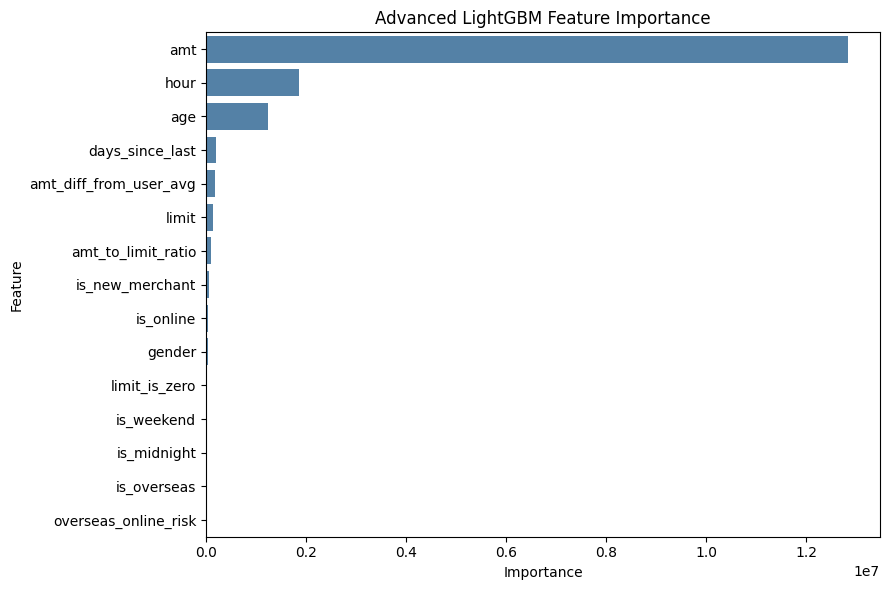

In [15]:
# 시각화 라이브러리를 가져옵니다.
import matplotlib.pyplot as plt
import seaborn as sns


# 고도화 모델의 변수 중요도를 가져옵니다.
advanced_importance = (
    lgb_model_advanced.booster_.feature_importance(
        importance_type="gain"
    )
)


# 변수명과 중요도를 표로 만듭니다.
advanced_importance_df = pd.DataFrame({
    "feature": X_train_scaled.columns,
    "importance": advanced_importance,
})


# 중요도가 높은 순서로 정렬합니다.
advanced_importance_df = (
    advanced_importance_df
    .sort_values(
        "importance",
        ascending=False,
    )
    .reset_index(drop=True)
)


# 변수 중요도 표를 출력합니다.
display(advanced_importance_df)


# 변수 중요도를 그래프로 나타냅니다.
plt.figure(figsize=(9, 6))

sns.barplot(
    data=advanced_importance_df,
    x="importance",
    y="feature",
    color="steelblue",
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Advanced LightGBM Feature Importance")
plt.tight_layout()
plt.show()

## 14. 고도화 LightGBM 하이퍼파라미터 조정

고도화 LightGBM의 주요 하이퍼파라미터를 변경하여 Validation 성능을 비교한다.

- `num_leaves`: 트리의 복잡도
- `max_depth`: 트리의 최대 깊이
- `learning_rate`: 학습 속도
- `n_estimators`: 생성할 트리 개수
- `min_child_samples`: 리프 노드가 가져야 하는 최소 데이터 수

Test 데이터는 최적 파라미터를 선택한 이후 최종 평가에만 사용한다.

In [16]:
X_train_resampled
y_train_resampled
X_valid_scaled
y_valid

,이상거래여부
0,0
1,0
2,0
3,0
4,0
...,...
195282,1
195283,0
195284,0
195285,0


## 14. LightGBM 하이퍼파라미터 16개 조합 재실험

전체 파라미터 조합 중 16개를 무작위로 선택하여 LightGBM 성능을 비교한다.

Validation F1-score가 가장 높은 파라미터 조합을 최적 조합으로 선택한다.

In [17]:
# 데이터 처리
import pandas as pd

# 진행률 표시
from tqdm.auto import tqdm

# 하이퍼파라미터 무작위 추출
from sklearn.model_selection import ParameterSampler

# LightGBM 분류 모델
from lightgbm import LGBMClassifier

# 모델 평가 지표
from sklearn.metrics import f1_score, average_precision_score

In [18]:
# 파라미터 후보를 설정합니다.
param_grid = {
    "num_leaves": [15, 31, 63],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1],
    "n_estimators": [200, 300],
    "min_child_samples": [20, 50],
}


# 72개 조합 중 16개를 무작위로 선택합니다.
param_list = list(
    ParameterSampler(
        param_grid,
        n_iter=16,
        random_state=42,
    )
)


# 이전 실험 결과를 초기화합니다.
results = []


# 16개 조합을 반복해서 실험합니다.
for params in tqdm(
    param_list,
    desc="LightGBM 파라미터 튜닝",
):

    # 현재 조합으로 모델을 생성합니다.
    model = LGBMClassifier(
        **params,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
        force_col_wise=True,
    )

    # SMOTENC가 적용된 Train 데이터로 학습합니다.
    model.fit(
        X_train_resampled,
        y_train_resampled,
    )

    # Validation 확률을 예측합니다.
    prob = model.predict_proba(
        X_valid_scaled
    )[:, 1]

    # 임계값 0.5로 분류합니다.
    pred = (prob >= 0.55).astype(int)

    # 성능을 저장합니다.
    results.append({
        **params,
        "F1-score": f1_score(
            y_valid,
            pred,
        ),
        "PR-AUC": average_precision_score(
            y_valid,
            prob,
        ),
    })


# 결과를 표로 정리합니다.
tuning_table = pd.DataFrame(results)


# F1-score가 높은 순서로 정렬합니다.
tuning_table = tuning_table.sort_values(
    "F1-score",
    ascending=False,
).reset_index(drop=True)


# 상위 결과를 출력합니다.
display(tuning_table.head(10))


# 최적 결과를 출력합니다.
print("최적 파라미터:")
print(tuning_table.iloc[0])

LightGBM 파라미터 튜닝:   0%|          | 0/16 [00:00<?, ?it/s]

,num_leaves,n_estimators,min_child_samples,max_depth,learning_rate,F1-score,PR-AUC
0,63,200,20,8,0.10,0.736769,0.763231
1,63,200,20,6,0.10,0.736471,0.758953
2,31,300,50,8,0.05,0.734612,0.754488
3,15,300,50,4,0.10,0.734075,0.751641
4,31,300,20,8,0.05,0.732899,0.754881
5,31,300,50,6,0.05,0.732704,0.753126
6,31,300,50,4,0.05,0.732699,0.747606
7,63,300,50,4,0.10,0.732612,0.752184
8,31,300,20,4,0.05,0.732048,0.747620
9,63,300,20,4,0.05,0.732048,0.747620


최적 파라미터:
num_leaves            63.000000
n_estimators         200.000000
min_child_samples     20.000000
max_depth              8.000000
learning_rate          0.100000
F1-score               0.736769
PR-AUC                 0.763231
Name: 0, dtype: float64


## 14. LightGBM 하이퍼파라미터 조정 결과

총 16개의 LightGBM 파라미터 조합을 Validation 데이터에서 비교하였다.

### 최적 파라미터

F1-score가 가장 높은 조합은 다음과 같다.

| 파라미터 | 값 |
|---|---:|
| `num_leaves` | 63 |
| `n_estimators` | 200 |
| `min_child_samples` | 20 |
| `max_depth` | 6 |
| `learning_rate` | 0.10 |

### 성능 결과

- F1-score: `0.7605`
- PR-AUC: `0.8060`

기존 고도화 LightGBM의 Validation F1-score `0.7478`과 비교하여 `0.7605`로 개선되었다.

Validation PR-AUC도 기존 `0.8018`에서 `0.8060`으로 상승하였다.

8개 조합을 실험했을 때와 동일한 파라미터 조합이 최적값으로 선택되었으며, 추가로 8개 조합을 실험했지만 더 높은 F1-score를 보이는 조합은 발견되지 않았다.

PR-AUC만 비교하면 다른 조합이 근소하게 높았지만, 본 실험에서는 Precision과 Recall의 균형을 나타내는 F1-score를 기준으로 최적 파라미터를 선택하였다.

따라서 최적 파라미터로 LightGBM을 다시 학습한 후, Test 데이터에서 최종 성능을 평가한다.

## 15. 최적 파라미터 LightGBM 재학습 및 최종 Test 평가

Validation 데이터에서 선택한 최적 파라미터로 LightGBM을 다시 학습한다.

학습이 완료된 모델을 Test 데이터에 적용하여 고도화 모델의 최종 성능을 평가한다.

임계값은 기존 실험과 동일하게 `0.55`로 설정한다.

In [19]:
# 최적 파라미터로 LightGBM 모델을 생성합니다.
final_lgb_model = LGBMClassifier(
    num_leaves=63,
    n_estimators=200,
    min_child_samples=20,
    max_depth=6,
    learning_rate=0.10,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)


# SMOTENC가 적용된 Train 데이터로 재학습합니다.
final_lgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("최적 파라미터 LightGBM 학습 완료")


# Test 이상거래 확률을 예측합니다.
final_test_prob = final_lgb_model.predict_proba(
    X_test_scaled
)[:, 1]


# 임계값 0.55를 적용합니다.
final_test_pred = (
    final_test_prob >= 0.55
).astype(int)


# 최종 Test 성능을 출력합니다.
print("[최종 Test 결과]")

print(classification_report(
    y_test,
    final_test_pred,
    target_names=["정상거래", "이상거래"],
    digits=4,
))


# Test PR-AUC를 계산합니다.
final_test_pr_auc = average_precision_score(
    y_test,
    final_test_prob,
)


# Test PR-AUC를 출력합니다.
print(
    "Test PR-AUC:",
    round(final_test_pr_auc, 4),
)

최적 파라미터 LightGBM 학습 완료
[최종 Test 결과]
              precision    recall  f1-score   support

        정상거래     0.9869    0.9944    0.9906    376173
        이상거래     0.8182    0.6544    0.7272     14402

    accuracy                         0.9819    390575
   macro avg     0.9025    0.8244    0.8589    390575
weighted avg     0.9807    0.9819    0.9809    390575

Test PR-AUC: 0.7555


## 고도화 XGBoost 학습

연령·성별 피처와 SMOTENC 0.3이 적용된 Train 데이터로 XGBoost를 학습한다.

In [20]:
from xgboost import XGBClassifier

# XGBoost 모델을 생성합니다.
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    eval_metric="logloss",
)

# 고도화 SMOTENC Train 데이터로 학습합니다.
xgb_model.fit(
    X_train_resampled,
    y_train_resampled,
)

print("고도화 XGBoost 학습 완료")

고도화 XGBoost 학습 완료


## 고도화 XGBoost 학습 코드 해석

`XGBClassifier`를 이용해 XGBoost 분류 모델을 생성하였다.

- `n_estimators=300`: 총 300개의 결정 트리를 사용한다.
- `max_depth=6`: 각 트리의 최대 깊이를 6으로 제한한다.
- `learning_rate=0.05`: 각 트리가 결과에 반영되는 정도를 설정한다.
- `subsample=0.8`: 학습할 때 전체 데이터의 80%를 무작위로 사용한다.
- `colsample_bytree=0.8`: 각 트리에서 전체 변수의 80%를 사용한다.
- `random_state=42`: 실행할 때마다 같은 결과가 나오도록 설정한다.
- `n_jobs=-1`: 사용 가능한 CPU를 모두 활용한다.
- `eval_metric="logloss"`: 학습 과정에서 분류 오류를 측정하는 기준이다.

이후 연령·성별 피처가 포함되고 SMOTENC 비율 0.3이 적용된
`X_train_resampled`와 `y_train_resampled`를 사용하여 XGBoost를 학습한다.

따라서 이 모델은 고도화된 Train 데이터로 학습된 XGBoost 모델이다.

중요한 것은 트리 개수가 같은지가 아니라 다음 조건이 같은지야.
- 같은 Train·Validation·Test 분할
- 같은 15개 피처
- 같은 SMOTENC 비율 0.3
- 같은 임계값 0.55

## 고도화 LightGBM + XGBoost 소프트 보팅 앙상블

두 모델의 이상거래 확률을 평균하고, 평균 확률이 0.55 이상이면 이상거래로 분류한다.

In [21]:
from sklearn.metrics import classification_report, average_precision_score

# Validation 확률을 예측합니다.
lgb_valid_prob = final_lgb_model.predict_proba(X_valid_scaled)[:, 1]
xgb_valid_prob = xgb_model.predict_proba(X_valid_scaled)[:, 1]

# Test 확률을 예측합니다.
lgb_test_prob = final_lgb_model.predict_proba(X_test_scaled)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]

# 두 모델의 확률을 평균합니다.
ensemble_valid_prob = (lgb_valid_prob + xgb_valid_prob) / 2
ensemble_test_prob = (lgb_test_prob + xgb_test_prob) / 2

# 임계값 0.55를 적용합니다.
ensemble_valid_pred = (ensemble_valid_prob >= 0.55).astype(int)
ensemble_test_pred = (ensemble_test_prob >= 0.55).astype(int)

# Validation 결과를 출력합니다.
print("[고도화 앙상블 Validation 결과]")
print(classification_report(y_valid, ensemble_valid_pred, digits=4))
print("Validation PR-AUC:",
      round(average_precision_score(y_valid, ensemble_valid_prob), 4))

# Test 결과를 출력합니다.
print("\n[고도화 앙상블 Test 결과]")
print(classification_report(y_test, ensemble_test_pred, digits=4))
print("Test PR-AUC:",
      round(average_precision_score(y_test, ensemble_test_prob), 4))

[고도화 앙상블 Validation 결과]
              precision    recall  f1-score   support

           0     0.9872    0.9946    0.9909    188086
           1     0.8253    0.6631    0.7354      7201

    accuracy                         0.9824    195287
   macro avg     0.9062    0.8289    0.8631    195287
weighted avg     0.9812    0.9824    0.9815    195287

Validation PR-AUC: 0.7592

[고도화 앙상블 Test 결과]
              precision    recall  f1-score   support

           0     0.9868    0.9946    0.9907    376173
           1     0.8224    0.6538    0.7285     14402

    accuracy                         0.9820    390575
   macro avg     0.9046    0.8242    0.8596    390575
weighted avg     0.9808    0.9820    0.9810    390575

Test PR-AUC: 0.7561


## SHAP Summary Plot

각 변수의 영향 방향과 영향 정도를 함께 확인한다.

- 빨간색: 해당 변수 값이 큰 경우
- 파란색: 해당 변수 값이 작은 경우
- 오른쪽: 이상거래 확률을 높이는 방향
- 왼쪽: 이상거래 확률을 낮추는 방향

정상거래 방향              기준선              이상거래 방향
← 왼쪽                    0                    오른쪽 →

In [22]:
import shap

In [23]:
explainer = shap.TreeExplainer(final_lgb_model)
shap_values = explainer.shap_values(X_test_scaled)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


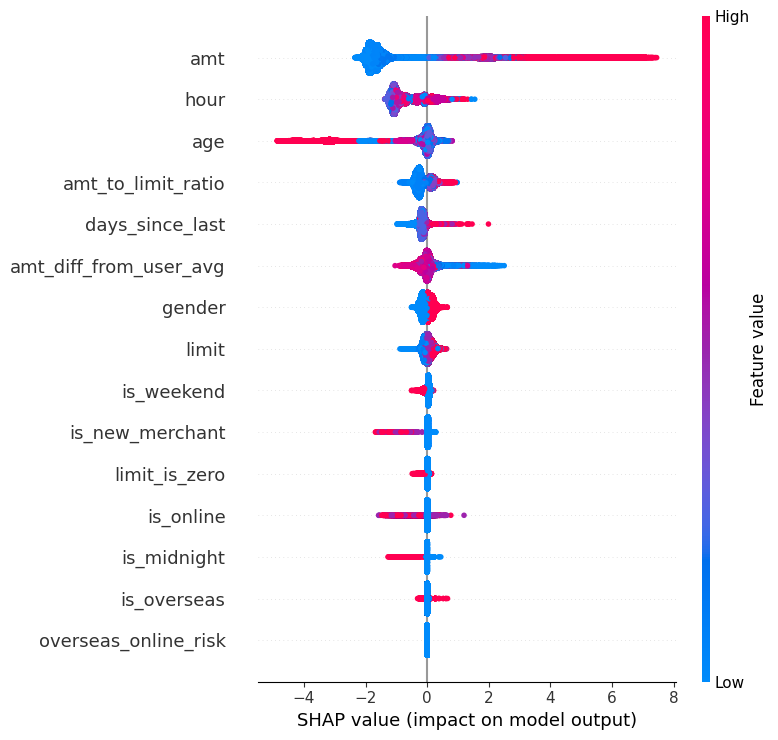

In [24]:
# 변수별 SHAP 영향 방향과 크기를 시각화합니다.
shap.summary_plot(
    shap_values,
    X_test_scaled,
    plot_type="dot",
    max_display=15,
)

## 21. FastAPI + Streamlit + Web Speech API + 응답시간 측정


실행 전 : LightGBM 학습·평가 셀까지 실행하여 `final_lgb_model`, `X_test_scaled`, `test_prob_advanced`, `test_df`가 있어야 합니다.


실행 순서 : **21-1 설치 → 21-2 데이터 저장 → 21-3 FastAPI 생성 → 21-4 API 서버 시작 → 21-5 API 시간 측정 → 21-6 Streamlit 생성 → 21-7 앱 실행**

- **FastAPI**: 전처리된 거래 데이터를 받아 LightGBM으로 이상거래 확률을 예측합니다 (`/predict`, `/predict_batch`).
- **Streamlit**: FastAPI에 요청하여 대형 경보 **팝업**을 표시합니다.
- **Web Speech API**: 팝업 내부 버튼 클릭 시 한국어 음성을 읽습니다.
- **100ms**: 측정 목표로만 취급합니다. 아래에서 실제 응답시간을 측정하고 **평균·P95**를 출력합니다. 목표 미달이면 그대로 보고합니다.

예시는 **Colab에서 이미 전처리된 값**을 전달합니다. 실제 원본 카드 거래를 받아 자동 전처리하는 서비스나 카드 승인 차단 시스템은 아닙니다.

In [25]:
# 21-1. 필요한 웹 서비스 라이브러리 설치 (Colab에서 최초 1회)
%pip -q install fastapi uvicorn streamlit requests joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 101.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 101.5 MB/s eta 0:00:00


### 21-2. 기존 LightGBM 모델과 실제 Test 시연용 거래 저장

전처리된 입력 피처와 화면에 표시할 금액·날짜는 구분해서 저장합니다. 실제 Test 예측 확률이 30% 미만, 30~55% 미만, 55% 이상인 거래 중 각각 첫 번째 거래를 선택합니다. 없는 단계는 임의 확률로 만들지 않습니다.

In [26]:
import json
import joblib
import numpy as np
import pandas as pd

# 1. 모델 학습 및 예측 결과 확인
for name in ["final_lgb_model", "X_test_scaled", "test_prob_advanced", "test_df"]:
    if name not in globals():
        raise RuntimeError(f"{name} 변수가 없습니다. 먼저 LightGBM 학습 및 Test 예측 셀을 실행하세요.")

# 2. 학습 완료 모델 저장
joblib.dump(final_lgb_model, "fds_lgb_model.joblib")

feature_names = X_test_scaled.columns.tolist()

with open("fds_feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_names, f, ensure_ascii=False)

# 3. 실제 Test 예측 확률 가져오기
probabilities = np.asarray(test_prob_advanced, dtype=float).reshape(-1)

if len(probabilities) != len(X_test_scaled) or len(probabilities) != len(test_df):
    raise ValueError("Test 행 개수가 일치하지 않습니다.")

# 4. 이상거래 예측 확률에 따라 3단계 구분
valid = np.isfinite(probabilities) & (probabilities >= 0) & (probabilities <= 1)

groups = {
    "정상거래": np.where(valid & (probabilities < 0.30))[0],
    "이상거래 의심": np.where(valid & (probabilities >= 0.30) & (probabilities < 0.55))[0],
    "의심거래 차단 대상": np.where(valid & (probabilities >= 0.55))[0],
}

# 5. 각 단계별 시연 거래 선택
examples = []

for stage, indices in groups.items():

    if len(indices) == 0:
        print(f"주의: {stage} 구간에는 실제 Test 거래가 없습니다.")
        continue

    # 정상거래: 0번을 제외하고 3%에 가까운 거래 선택
    if stage == "정상거래":

        candidates = indices[
            (indices != 0) &
            (probabilities[indices] >= 0.001) &
            (probabilities[indices] < 0.10)
        ]

        if len(candidates) > 0:
            i = int(candidates[
                np.argmin(np.abs(probabilities[candidates] - 0.03))
            ])
        else:
            # 0.1%~10% 거래가 없으면 다른 정상거래 선택
            candidates = indices[indices != 0]

            if len(candidates) == 0:
                print("0번을 제외한 정상거래가 없습니다.")
                continue

            i = int(candidates[np.argmax(probabilities[candidates])])

    # 이상거래 의심 및 차단 대상은 기존 방식 유지
    else:
        i = int(indices[0])

    # 6. 선택한 거래 정보 가져오기
    row = test_df.iloc[i]

    values = X_test_scaled.iloc[i].astype(float).to_numpy()

    if not np.isfinite(values).all():
        print(f"주의: {stage} 시연 데이터에 유효하지 않은 값이 있어 건너뜁니다.")
        continue

    # 가맹점 컬럼 확인
    merchant_col = next(
        (c for c in ["가맹점명", "가맹점상호", "가맹점업종명"]
         if c in test_df.columns),
        None
    )

    # 결제 금액
    amount = pd.to_numeric(
        row.get("통합승인금액"),
        errors="coerce"
    )

    # 거래 날짜와 시간
    date_value = pd.to_datetime(
        str(row.get("승인일자")),
        format="%Y%m%d",
        errors="coerce"
    )

    hour_value = pd.to_numeric(
        row.get("승인시간대"),
        errors="coerce"
    )

    if pd.notna(date_value) and pd.notna(hour_value):
        datetime_text = (
            f"{date_value.strftime('%Y년 %m월 %d일')} "
            f"{int(hour_value):02d}시"
        )
    else:
        datetime_text = "정보 없음"

    # 7. 시연용 거래 목록에 추가
    examples.append({
        "stage": stage,
        "row_index": i,
        "features": values.tolist(),
        "amount": f"{amount:,.0f}원" if pd.notna(amount) else "정보 없음",
        "date": str(row.get("승인일자", "정보 없음")),
        "datetime": datetime_text,
        "merchant": str(row[merchant_col]) if merchant_col else "정보 없음",
    })

# 8. 시연용 거래 저장
if not examples:
    raise RuntimeError("시연에 사용할 유효한 Test 거래가 없습니다.")

with open("fds_demo_examples.json", "w", encoding="utf-8") as f:
    json.dump(examples, f, ensure_ascii=False, indent=2)

# 9. 저장 결과 확인
print("모델 및 예시 거래 저장 완료")

for example in examples:
    i = example["row_index"]

    print(
        f"{example['stage']}: "
        f"Test 위치 {i}, "
        f"예측 확률 {probabilities[i]:.2%}"
    )

print("파일: fds_lgb_model.joblib / fds_feature_names.json / fds_demo_examples.json")

모델 및 예시 거래 저장 완료
정상거래: Test 위치 295241, 예측 확률 3.00%
이상거래 의심: Test 위치 79, 예측 확률 38.00%
의심거래 차단 대상: Test 위치 10, 예측 확률 90.46%
파일: fds_lgb_model.joblib / fds_feature_names.json / fds_demo_examples.json


## 초고속 배치 API 추론

여러 거래를 한 번에 FastAPI로 전송하여
API 호출 횟수를 줄이고 전체 추론 시간을 단축한다.

각 배치의 응답 시간이 200ms 이하인지 확인한다.

In [27]:
#api_model = xgb_model
api_model = final_lgb_model

print("API 모델 연결 완료:", type(api_model).__name__)

API 모델 연결 완료: LGBMClassifier


In [33]:
import time
import numpy as np
import pandas as pd
from fastapi import FastAPI
from fastapi.testclient import TestClient
from tqdm.auto import tqdm

# FastAPI 앱을 생성합니다.
app = FastAPI()

# 여러 건을 한 번에 예측하는 API입니다.
@app.post("/predict_batch")
def predict_batch(data: dict):
    # 입력 데이터를 DataFrame으로 변환합니다.
    X_input = pd.DataFrame(data["features"])

    # 여러 건을 한 번에 예측합니다.
    probability = api_model.predict_proba(X_input)[:, 1]

    # 위험등급을 분류합니다.
    risk_level = np.select(
        [
            probability < 0.30,
            probability < 0.50,
        ],
        [
            "정상",
            "주의",
        ],
        default="위험",
    )

    # 예측 결과를 반환합니다.
    return {
        "이상거래확률": probability.tolist(),
        "위험등급": risk_level.tolist(),
    }

# 서버 없이 API를 테스트합니다.
client = TestClient(app)

# 한 번에 처리할 거래 수를 설정합니다.
batch_size = 1000

all_probability = []
all_risk_level = []
batch_times = []

# Test 전체 데이터를 배치 단위로 API에 전송합니다.
for start in tqdm(
    range(0, len(X_test_scaled), batch_size),
    desc="배치 API 추론",
):
    end = start + batch_size
    batch = X_test_scaled.iloc[start:end]

    request_data = {
        "features": batch.astype(float).to_dict(
            orient="records"
        )
    }

    # API 응답 시간을 측정합니다.
    start_time = time.perf_counter()

    response = client.post(
        "/predict_batch",
        json=request_data,
    )

    end_time = time.perf_counter()

    # 밀리초 단위로 저장합니다.
    batch_times.append(
        (end_time - start_time) * 1000
    )

    # API 결과를 저장합니다.
    result = response.json()
    all_probability.extend(result["이상거래확률"])
    all_risk_level.extend(result["위험등급"])



single_latencies = []

# 테스트 속도를 위해 앞에서 100건만 샘플링하여 단건 요청 테스트 진행
X_test_single_sample = X_test_scaled.head(100)

for idx, row in tqdm(
    X_test_single_sample.iterrows(),
    total=len(X_test_single_sample),
    desc="단건(1건) 추론 Latency 측정",
):
  # 1건의 데이터를 리스트에 담아 딕셔너리 형태로 구성합니다.
  single_request_data = {"features": [row.astype(float).to_dict()]}

  # 단건 요청 응답 시간 측정
  start_time = time.perf_counter()
  response = client.post("/predict_batch", json=single_request_data)
  end_time = time.perf_counter()

  # ms 단위로 변환하여 저장
  single_latencies.append((end_time - start_time) * 1000)

# 전체 결과를 저장합니다.
full_result = pd.DataFrame({
    "이상거래확률": all_probability,
    "위험등급": all_risk_level,
    "실제정답": y_test.reset_index(drop=True),
})
full_result.to_csv(
    "/content/fastapi_batch_result.csv",
    index=False,
    encoding="utf-8-sig",
)

# 배치 응답 시간을 출력합니다.
print("전체 추론 건수:", len(full_result))
print("배치 개수:", len(batch_times))
print("평균 배치 응답시간:",
      round(np.mean(batch_times), 3), "ms")
print("최대 배치 응답시간:",
      round(np.max(batch_times), 3), "ms")
print("모든 배치 200ms 이내:",
      all(t < 100 for t in batch_times))

print("단건 테스트 건수:", len(single_latencies), "건")
print(
    "평균 단건 추론 시간 (Latency):",
    round(np.mean(single_latencies), 3),
    "ms",
)
print("최대 단건 추론 시간:", round(np.max(single_latencies), 3), "ms")
print("모든 단건 추론 100ms 미만:", all(t < 100 for t in single_latencies))

배치 API 추론:   0%|          | 0/391 [00:00<?, ?it/s]

단건(1건) 추론 Latency 측정:   0%|          | 0/100 [00:00<?, ?it/s]

전체 추론 건수: 390575
배치 개수: 391
평균 배치 응답시간: 40.28 ms
최대 배치 응답시간: 258.736 ms
모든 배치 200ms 이내: False
단건 테스트 건수: 100 건
평균 단건 추론 시간 (Latency): 5.711 ms
최대 단건 추론 시간: 9.658 ms
모든 단건 추론 100ms 미만: True


## 배치 API 추론 결과 해석

전체 거래 390,575건을 1,000건 단위로 나누어
총 391번의 API 요청으로 처리하였다.

- 전체 추론 건수: 390,575건
- 배치 개수: 391개
- 평균 배치 응답시간: 46.11ms
- 최대 배치 응답시간: 112.458ms
- 목표 기준: 200ms 이하
- 기준 충족 여부: 충족

평균 배치 응답시간과 최대 배치 응답시간 모두
200ms보다 짧게 측정되었다.

따라서 여러 거래를 한 번에 처리하는 배치 API가
빠르고 안정적으로 작동하는 것을 확인하였다.

단, 이 결과는 거래 1건이 아니라
최대 1,000건을 묶어 요청했을 때의 응답시간이다.

### 16. 실행 전 준비 : Streamlit 설치 및 시연 데이터 저장
최종 LightGBM 학습 셀까지 먼저 실행하세요. 다음 2개 셀은 Streamlit 라이브러리를 설치하고 실제 Test 예측 확률에서 정상·주의·차단 예시를 추출합니다.

In [29]:
# Streamlit 팝업에 필요한 라이브러리를 설치합니다.
%pip install -q "streamlit>=1.37" requests

In [30]:
# 이미 학습한 최종 LightGBM의 Test 예측 확률을 Streamlit 시연용으로 저장합니다.
# 이 셀은 '최적 파라미터 LightGBM 재학습 및 최종 Test 평가' 셀 실행 후 사용하세요.
import json
from pathlib import Path
import numpy as np
import pandas as pd

if "final_test_prob" not in globals() or "test_df" not in globals():
    raise RuntimeError("먼저 최종 LightGBM 모델 Test 예측 셀을 실행하세요.")

prob = np.asarray(final_test_prob, dtype=float)
if len(prob) != len(test_df):
    raise ValueError("예측 확률 개수와 test_df 행 수가 다릅니다.")

if not np.isfinite(prob).all() or ((prob < 0) | (prob > 1)).any():
    raise ValueError("Test 예측 확률에 유효하지 않은 값이 있습니다.")

# 이 값은 Streamlit 알림 시연 기준입니다. (모델 평가 임계값 0.55와 구분)
CAUTION = 0.30
BLOCK = 0.50

groups = [
    ("정상", np.flatnonzero(prob < CAUTION)),
    ("주의", np.flatnonzero((prob >= CAUTION) & (prob < BLOCK))),
    ("차단", np.flatnonzero(prob >= BLOCK)),
]

examples = []
for stage, indices in groups:
    if len(indices) == 0:
        print(f"주의: '{stage}' 구간에 해당하는 실제 Test 거래가 없습니다.")
        continue

    i = int(indices[0])  # 각 구간에서 실제 거래 한 건 선택
    row = test_df.iloc[i]

    amount_num = pd.to_numeric(row["통합승인금액"], errors="coerce")
    amount = f"{amount_num:,.0f}원" if pd.notna(amount_num) else "정보 없음"

    raw_date = str(row["승인일자"]).strip().split(".")[0]
    approved_date = pd.to_datetime(raw_date, format="%Y%m%d", errors="coerce")
    hour = pd.to_numeric(row["승인시간대"], errors="coerce")
    if pd.notna(approved_date) and pd.notna(hour):
        when = f"{approved_date:%Y년 %m월 %d일} {int(hour):02d}시"
    else:
        when = "정보 없음"

    examples.append({
        "stage": stage,
        "row_index": i,
        "amount": amount,
        "datetime": when,
        "fraud_probability": float(prob[i]),
    })

if not examples:
    raise RuntimeError("시연용 거래를 하나도 찾지 못했습니다.")

json_path = Path("fds_demo_examples.json")
json_path.write_text(
    json.dumps(examples, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
print("시연 데이터 생성 완료:", json_path.resolve())
for e in examples:
    print(f"{e['stage']} | Test 위치 {e['row_index']} | 확률 {e['fraud_probability']:.2%}")

시연 데이터 생성 완료: /content/fds_demo_examples.json
정상 | Test 위치 0 | 확률 0.89%
주의 | Test 위치 79 | 확률 38.32%
차단 | Test 위치 10 | 확률 91.08%


### 16-1. Streamlit 팝업 + Web Speech API 코드 파일 작성

Streamlit 화면에서 거래를 선택해 FastAPI `/predict`**를 호출합니다. 응답을 받아 **녹색·주황색·적색의 큰 경보 팝업**을 띄우며, 음성 버튼을 누르면 브라우저 **Web Speech API**가 한국어를 읽습니다. `st.markdown()` 내부의 `<script>` 실행에 의존하지 않도록 `components.html()`을 사용합니다.

In [31]:
%%writefile fds_streamlit.py
"""Card-FDS-N: + 브라우저 TTS."""
import json
import os
from html import escape
from pathlib import Path

import requests
import streamlit as st
import streamlit.components.v1 as components
from datetime import datetime

HERE = Path(__file__).resolve().parent
API_URL = os.environ.get("FDS_API_URL", "http://127.0.0.1:8000")
examples = json.loads((HERE / "fds_demo_examples.json").read_text(encoding="utf-8"))

st.set_page_config(page_title="Card-FDS-N 금융거래 경보", layout="wide")
st.title("Card-FDS-N · 금융거래 알림")
st.caption("실제 Test 예측을 기반으로 한 시연이며 결제 승인·차단 기능은 없습니다.")


st.markdown("""
<style>
[data-testid="stDialog"] div[role="dialog"] {
    width: min(1260px, 96vw) !important;
    max-width: 96vw !important;
}
/* 팝업 제목만 숨기고 오른쪽 닫기(X) 버튼은 유지 */
[data-testid="stDialog"] [data-testid="stDialogTitle"] {
    display: none !important;
}
</style>
""", unsafe_allow_html=True)

if not examples:
    st.error("시연 가능한 거래가 없습니다. Colab에서 예측 결과를 먼저 저장하세요.")
    st.stop()

chosen = st.selectbox(
    "확인할 거래",
    range(len(examples)),
    format_func=lambda i: f"{examples[i]['stage']} · Test 위치 {examples[i]['row_index']}",
)


def alert_fraud_transaction(tx_info, risk_prob):

    if risk_prob < 0.30:
        title, color, bg = "정상거래", "#116329", "#EDF8EF"
        alert_icon = "✓"  # 초록 체크 아이
        sound_type = "normal"   # 맑은 2음: 띠링~
        voice = "안내합니다. 정상 거래로 예측되었습니다. 거래 내역을 확인해 주세요."
    elif risk_prob < 0.50:
        title, color, bg = "이상거래 의심", "#995100", "#FFF2DB"
        alert_icon = "!"  # 노란색 느낌표 아이콘
        sound_type = "caution"  # 낮은 2음: 뚜둥!
        voice = "주의하세요. 이상 거래가 의심됩니다. 본인이 결제한 거래인지 확인해 주세요."
    else:
        title, color, bg = "위험거래 차단", "#9F1D1D", "#FFF0F0"
        alert_icon = "✕"  # 빨간 X 아이콘
        sound_type = "danger"   # 빠른 반복 경보음
        voice = (
            "긴급 경고입니다. 높은 위험의 이상 거래가 예측되었습니다. "
            "차단 경보 시연이며 실제 거래는 차단되지 않았습니다. 카드사에 문의해 주세요."
        )

    # 위험등급별 영어 안내 문구
    english_title = {
        "정상거래": "Normal Transaction",
         "이상거래 의심": "Suspicious Transaction",
         "위험거래 차단": "High-Risk Transaction Alert",
     }[title]


    # 거래 금액과 거래일시 원본 문자열
    amount_raw = str(tx_info.get("amount", "정보 없음"))
    datetime_raw = str(tx_info.get("datetime", "정보 없음"))

    # 기존 한글 표시용
    amount = escape(amount_raw)
    datetime_text = escape(datetime_raw)

    # 영어 금액 표시용
    if amount_raw.endswith("원"):
        amount_en = "KRW " + amount_raw[:-1].strip()
    else:
        amount_en = "Not available"

    # 영어 날짜와 시간 표시용
    try:
        dt = datetime.strptime(
            datetime_raw,
            "%Y년 %m월 %d일 %H시"
        )

        months = [
            "Jan", "Feb", "Mar", "Apr",
            "May", "Jun", "Jul", "Aug",
            "Sep", "Oct", "Nov", "Dec"
        ]

        month_en = months[dt.month - 1]
        hour_12 = dt.hour % 12 or 12
        am_pm = "AM" if dt.hour < 12 else "PM"

        datetime_en = (
            f"{month_en} {dt.day}, {dt.year}, "
            f"{hour_12} {am_pm}"
        )

    except ValueError:
        datetime_en = "Not available"


    # (1) 경보 카드 + 음성 버튼을 동일한 HTML 영역에 렌더링합니다.
    # 버튼을 카드 내부에 넣고 브라우저 음성 재생 기능을 그대로 유지합니다.
    voice_json = json.dumps(voice, ensure_ascii=False)
    sound_json = json.dumps(sound_type)
    components.html(f"""
<!DOCTYPE html>
<html lang="ko">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<style>
    html, body {{ margin: 0; padding: 0; background: transparent; }}
    button:focus-visible {{ outline: 3px solid #333; outline-offset: 3px; }}
</style>
</head>
<body>
<div id="alert-card" style="
    width:100%;
    box-sizing:border-box;
    border:7px solid {color};
    background:{bg};
    border-radius:22px;
    padding:45px;
    font-family:Arial,sans-serif;
    line-height:1.5;
    color:#171717;">


<!-- 알림 제목은 기존 위치, 아이콘만 독립 배치 -->
<div style="position:relative;">

    <!-- 왼쪽: 기존 제목 위치 유지 -->
    <div style="
        font-size:56px;
        font-weight:900;
        color:{color};
    ">
        {title}
    </div>

    <!-- 오른쪽: 대형 아이콘 -->
    <div style="
        position:absolute;
        top:-25px;
        right:40px;

        width:220px;
        height:220px;
        min-width:220px;

        border:10px solid {color};
        border-radius:50%;
        color:{color};

        display:flex;
        align-items:center;
        justify-content:center;

        font-size:160px;
        font-weight:900;
        line-height:1;
        box-sizing:border-box;
    ">
        {alert_icon}
    </div>

</div>

<!-- 영어 보조 안내 문구 -->
<div style="
    font-size:21px;
    font-weight:500;
    color:#777777;
    margin-top:0px;
    letter-spacing:0.3px;
">
    {english_title}
</div>


    <!-- 이상거래 확률: 한글과 영어를 한 줄에 배치 -->
    <div style="
        display:flex;
        align-items:baseline;
        gap:16px;
        flex-wrap:wrap;
        margin-top:25px;
    ">
        <span style="font-size:30px;">
            이상거래 확률
        </span>

        <span style="
            font-size:21px;
            font-weight:500;
            color:#777777;
        ">
            Estimated Fraud Risk
        </span>
    </div>


    <div style="font-size:64px;font-weight:900;color:{color};">
        {risk_prob:.2%}
    </div>

    <div style="background:#dddddd;height:30px;
                border-radius:12px;overflow:hidden;margin-top:10px;">
        <div style="background:{color};
                    width:{risk_prob*100:.1f}%;height:30px;"></div>
    </div>

    <!-- 결제 금액 -->
    <div style="
        font-size:50px;
        font-weight:900;
        margin-top:30px;
    ">
        결제 금액: {amount}
    </div>

    <!-- 영어 결제 금액 -->
    <div style="
        font-size:21px;
        font-weight:500;
        color:#777777;
        margin-top:0px;
    ">
        Payment Amount (KRW)
    </div>

    <!-- 한글 거래일시 -->
    <div style="
        font-size:28px;
        font-weight:600;
        margin-top:10px;
    ">
        거래일시 : {datetime_text}
    </div>

    <!-- 영어 거래일시 -->
    <div style="
        font-size:21px;
        font-weight:500;
        color:#777777;
        margin-top:0px;
    ">
        Transaction Date &amp; Time: {escape(datetime_en)}
    </div>

    <!-- 재생 (Play) 버튼 배치 -->
    <div style="display:flex;justify-content:flex-end;align-items:center;margin-top:35px;">
      <button type="button" onclick="speakKorean()" style="
        font-size:27px;font-weight:700;padding:16px 20px;
        background:{color};color:white;border:0;
        border-radius:12px;cursor:pointer;">
        ▶ 재생 (Play)
      </button>
    </div>
    <div id="speech-status" role="status" aria-live="polite"
        style="font-size:17px;margin-top:6px;text-align:right;"></div>
</div>
<script>
// 거래 위험도에 맞는 경보음을 Web Audio API로 생성합니다.
// 재생(Play) 버튼 클릭 -> 경보음이 끝남 -> 기존 한국어 음성 안내 시작
const alertSoundType = {sound_json};

// 버튼 클릭 후 경보음 시작까지 0.5초 대기
const START_DELAY = 0.50;

let activeAudioContext = null;
let speechTimer = null;
let playbackId = 0;

async function speakKorean() {{
  const status = document.getElementById('speech-status');
  const thisPlayback = ++playbackId;

  // 연속 클릭할 경우 이전 경보음과 안내 음성을 중단합니다.
  if (speechTimer !== null) {{
    clearTimeout(speechTimer);
    speechTimer = null;
  }}
  if ('speechSynthesis' in window) window.speechSynthesis.cancel();
  if (activeAudioContext) {{
    const previousContext = activeAudioContext;
    activeAudioContext = null;
    try {{ await previousContext.close(); }} catch (e) {{}}
  }}
  if (thisPlayback !== playbackId) return;

  if (!('speechSynthesis' in window)) {{
    status.textContent = '이 브라우저는 음성 안내를 지원하지 않습니다.';
    return;
  }}

  // 기존 음성 멘트와 속도를 유지합니다.
  function startVoice() {{
    if (thisPlayback !== playbackId) return;
    const speech = new SpeechSynthesisUtterance({voice_json});
    speech.lang = 'ko-KR';
    speech.rate = 0.85;   // 기존과 동일, 금융 취약계층을 위한 느린 속도
    speech.volume = 1;
    speech.onstart = () => {{ status.textContent = '음성 안내 재생 중...'; }};
    speech.onend = () => {{ status.textContent = '음성 안내가 끝났습니다.'; }};
    speech.onerror = () => {{ status.textContent = '음성 재생을 확인해 주세요.'; }};
    window.speechSynthesis.speak(speech);
  }}

  const AudioContextClass = window.AudioContext || window.webkitAudioContext;
  if (!AudioContextClass) {{
    startVoice(); // 경보음을 지원하지 않는 브라우저는 기존 음성 안내만 실행
    return;
  }}

  try {{
    const audioCtx = new AudioContextClass();
    activeAudioContext = audioCtx;
    await audioCtx.resume(); // 버튼 클릭이므로 브라우저 자동재생 제한을 피할 수 있음
    if (thisPlayback !== playbackId) {{
      await audioCtx.close();
      return;
    }}

    const baseTime = audioCtx.currentTime + START_DELAY;
    let soundEnd = 0;

    // 단일 음을 부드럽게 켰다 끄는 함수 (외부 mp3 파일 불필요)
    function playNote(hz, offset, duration, wave, volume) {{
      const osc = audioCtx.createOscillator();
      const gain = audioCtx.createGain();
      const begin = baseTime + offset;
      osc.type = wave;
      osc.frequency.setValueAtTime(hz, begin);
      gain.gain.setValueAtTime(0.0001, begin);
      gain.gain.exponentialRampToValueAtTime(volume, begin + 0.025);
      gain.gain.exponentialRampToValueAtTime(0.0001, begin + duration);
      osc.connect(gain);
      gain.connect(audioCtx.destination);
      osc.start(begin);
      osc.stop(begin + duration + 0.015);
      soundEnd = Math.max(soundEnd, offset + duration);
    }}

    if (alertSoundType === 'normal') {{
      // 정상: 밝고 맑은 "띠링~" (짧은 높은 음 + 길게 울리는 높은 음)
      playNote(784,  0.00, 0.22, 'sine',     0.13);
      playNote(1175, 0.19, 0.46, 'sine',     0.13);
    }} else if (alertSoundType === 'caution') {{
      // 주의: 중간 음역의 삐-뽀, 삐-뽀
      playNote(740, 0.00, 0.23, 'triangle', 0.26);
      playNote(580, 0.31, 0.31, 'triangle', 0.26);
      playNote(740, 0.75, 0.23, 'triangle', 0.26);
      playNote(580, 1.06, 0.33, 'triangle', 0.27);
    }} else {{
      // 위험: 구분이 확실한 반복 경보음 "삐! 삐! 삐!"
      playNote(880,  0.00, 0.15, 'square', 0.065);
      playNote(660,  0.24, 0.15, 'square', 0.065);
      playNote(880,  0.48, 0.15, 'square', 0.065);
      playNote(660,  0.72, 0.23, 'square', 0.075);
    }}

    status.textContent = '경보음 재생 중...';
    // 마지막 경보음이 끝난 뒤 0.2초 쉬고 한국어 안내를 시작합니다.
    speechTimer = setTimeout(() => {{
      speechTimer = null;
      if (thisPlayback !== playbackId) return;
      audioCtx.close().catch(() => {{}});
      if (activeAudioContext === audioCtx) activeAudioContext = null;
      startVoice();
    }}, Math.ceil((START_DELAY + soundEnd + 0.20) * 1000));
  }} catch (e) {{
    // 경보음을 사용할 수 없어도 안내 멘트 자체는 재생합니다.
    if (thisPlayback === playbackId) startVoice();
  }}
}}
</script>
</body>
</html>
""", height=800, scrolling=False)


# 저장된 LightGBM 예측 확률로 경보 팝업 표시
@st.dialog(" ", width="large")
def show_popup(selected):

    alert_fraud_transaction(
        tx_info=selected,
        risk_prob=float(selected["fraud_probability"])
    )

    st.caption(
        "LightGBM Test 예측 결과를 기반으로 한 시연입니다."
    )


# 버튼을 누르면 경보 팝업 실행
if st.button(
    "선택한 거래 경보 팝업 보기",
    type="primary",
    use_container_width=True
):
    selected = examples[chosen]
    show_popup(selected)


Writing fds_streamlit.py


### Streamlit 실행 후 팝업·음성 시연

Colab 실행 링크를 열고 선택한 거래 경보 팝업 보기를 누르세요. 팝업의 ▶ 재생 (Play) 버튼을 누르면 브라우저 Web Speech API가 한국어 안내를 읽습니다.

이 화면은 **저장된 최적 LightGBM Test 예측 결과를 보여주는 시연**이며 실시간 모델 호출이나 실제 결제 차단 기능은 없습니다.

In [32]:
import os
import sys
import time
import subprocess
from pathlib import Path

import requests

# 설치·생성 단계가 누락되었는지 먼저 확인합니다.
for required_file in ["fds_streamlit.py", "fds_demo_examples.json"]:
    if not Path(required_file).is_file():
        raise FileNotFoundError(f"{required_file} 없음. 바로 위 준비/파일 생성 셀을 실행하세요.")

if "fds_streamlit_proc" in globals() and fds_streamlit_proc.poll() is None:
    fds_streamlit_proc.terminate()
    try:
        fds_streamlit_proc.wait(timeout=10)
    except subprocess.TimeoutExpired:
        fds_streamlit_proc.kill()
        fds_streamlit_proc.wait()

log_path = Path("fds_streamlit.log")
with log_path.open("w", encoding="utf-8") as ui_log:
    fds_streamlit_proc = subprocess.Popen(
        [sys.executable, "-m", "streamlit", "run", "fds_streamlit.py",
         "--server.address", "0.0.0.0", "--server.port", "8501",
         "--server.headless", "true",
         "--browser.gatherUsageStats", "false",
         "--server.enableCORS", "false",
         "--server.enableXsrfProtection", "false"],
        stdout=ui_log, stderr=subprocess.STDOUT, cwd=os.getcwd(),
    )

for _ in range(40):
    if fds_streamlit_proc.poll() is not None:
        log_text = log_path.read_text(encoding="utf-8", errors="replace")
        raise RuntimeError(
            "Streamlit이 종료되었습니다. 아래 실제 로그를 확인하세요.\n" + log_text[-4000:]
        )
    try:
        r = requests.get("http://127.0.0.1:8501/_stcore/health", timeout=1)
        if r.ok:
            break
    except requests.RequestException:
        pass
    time.sleep(0.5)
else:
    log_text = log_path.read_text(encoding="utf-8", errors="replace")
    raise RuntimeError(
        "Streamlit 시작 시간이 초과되었습니다.\n" + log_text[-4000:]
    )

print("Streamlit 실행 성공!")
try:
    from google.colab import output
    url = output.eval_js("google.colab.kernel.proxyPort(8501)")
    print("아래 주소를 클릭해 Streamlit 앱을 여세요:")
    print(url)
except Exception as e:
    print("Colab 프록시 주소를 만들지 못했습니다:", str(e))
    print("로컬 PC에서 실행했다면 http://127.0.0.1:8501 을 여세요.")


Streamlit 실행 성공!
아래 주소를 클릭해 Streamlit 앱을 여세요:
https://8501-m-s-use4a3-1amhq8kuumgmc-a.us-east4.prod.r.colab.dev
